**Prompt:** The main section is called "Credit Card Fraud: Exploratory Data Analysis". State that the class is MAT 311, which is entitled Introduction to Data Science. State that I used Claude Sonnet 5.5 and that it wrote the code and visualizations.

**AI:** Claude Sonnet 5.5

# Credit Card Fraud: Exploratory Data Analysis

**Class:** MAT 311: Introduction to Data Science

**AI system used:** Claude Sonnet 5.5 (Anthropic). Claude Sonnet 5.5 wrote the code and visualizations in this notebook, based on the prompts shown throughout.

**Prompt:** The first section is "Data Context". State where the data is from (Kaggle) and that this is the link (https://www.kaggle.com/datasets/dhanushnarayananr/credit-card-fraud). Also, discuss how the data had no institution named as the publisher. Finally, make a two-column table with the dataset's columns in one column and their explanations in the other.

**AI:** Claude Sonnet 5.5

## Data Context

The data comes from **Kaggle**, from a public dataset of credit card transactions labelled as fraudulent or legitimate: <https://www.kaggle.com/datasets/dhanushnarayananr/credit-card-fraud>. The dataset page does not say which institution originally produced the data. Each row is a single transaction. The file used in this notebook (`card_transdata.csv`) contains the columns below.

| Column | Explanation |
|---|---|
| `distance_from_home` | Distance between the cardholder's home and the location where the transaction took place |
| `distance_from_last_transaction` | Distance between the location of this transaction and the location of the previous transaction |
| `ratio_to_median_purchase_price` | Ratio of the transaction's purchase price to the median purchase price (1 means a typical amount, 5 means five times the median) |
| `repeat_retailer` | Whether the transaction happened at a retailer the cardholder has used before (1 = yes, 0 = no) |
| `used_chip` | Whether the card's chip was used for the transaction (1 = yes, 0 = no) |
| `used_pin_number` | Whether a PIN was entered during the transaction (1 = yes, 0 = no) |
| `online_order` | Whether the transaction was an online order (1 = yes, 0 = no) |
| `fraud` | The target variable: whether the transaction was fraudulent (1 = fraud, 0 = legitimate) |

The three numeric columns are continuous measurements, and the other five are binary (yes/no) indicators.

**Prompt:** The next section is called "First Day of Data Science with Python". Have Professor Amish Mishra write a short welcome to the first day of class message.

**AI:** Claude Sonnet 5.5

## First Day of Data Science with Python

Welcome to MAT 311: Introduction to Data Science!

Today is the first day of our journey into working with data using Python. By the end of this course you will be able to load a dataset, explore it, visualize it, and ask questions of it with confidence. Don't worry if the code looks unfamiliar right now. Everyone starts somewhere, and the goal today is simply to see what is possible.

To get us started, we will look at a real-world problem: credit card fraud. Let's dig in!

*Dr. Amish Mishra*

**Prompt:** Now we will load in the libraries. We need to import pandas, seaborn, matplotlib.pyplot, and plotly.express. Use the standard naming conventions for the first three and import plotly.express as px. Have this section name be 'Load Necessary Libraries'

**AI:** Claude Sonnet 5.5

## Load Necessary Libraries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

**Prompt:** Now load in the csv file and rename it to transaction_data_raw and display the first few rows. Have the section name be 'Load the Data'

**AI:** Claude Sonnet 5.5

## Load the Data

In [2]:
transaction_data_raw = pd.read_csv('card_transdata.csv')
transaction_data_raw.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


**Prompt:** Let's now inspect the shape and the information of the raw data.

**AI:** Claude Sonnet 5.5

In [3]:
transaction_data_raw.shape

(999, 8)

In [4]:
transaction_data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


**Prompt:** Now, describe the data and check for missing values. Also, have a section named 'Data Wrangling' that intersects the description and checking for missing values. Then explain why dropping the missing rows is reasonable.

**AI:** Claude Sonnet 5.5

In [5]:
transaction_data_raw.describe()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,999.000000,996.000000,997.000000,992.000000,995.000000,997.000000,995.000000,999.000000
mean,26.876607,5.437319,1.655069,0.892137,0.313568,0.117352,0.673367,0.079079
std,63.899697,35.668094,2.351386,0.310364,0.464176,0.322001,0.469218,0.269997
min,0.104184,0.001448,0.016933,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.990543,0.306441,0.468123,1.000000,0.000000,0.000000,0.000000,0.000000
50%,10.340321,0.958539,0.955504,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.393952,3.137259,1.922025,1.000000,1.000000,0.000000,1.000000,0.000000
max,965.910612,990.070315,36.074366,1.000000,1.000000,1.000000,1.000000,1.000000


## Data Wrangling

In [6]:
transaction_data_raw.isna().sum()

distance_from_home                0
distance_from_last_transaction    3
ratio_to_median_purchase_price    2
repeat_retailer                   7
used_chip                         4
used_pin_number                   2
online_order                      4
fraud                             0
dtype: int64

Some columns contain missing values: 22 of the 999 rows (about 2%) have at least one blank. Because so few rows are affected, the simplest sound choice is to drop them. This keeps every remaining value real instead of replacing blanks with guesses, and it removes very little data.

**Prompt:** Now drop the values that are missing, print the shape, and display the first few rows of the new dataset.

**AI:** Claude Sonnet 5.5

In [7]:
transaction_data = transaction_data_raw.dropna()
print(transaction_data.shape)
transaction_data.head()

(977, 8)


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0
5,5.586408,13.261073,0.064768,1.0,0.0,0.0,0.0,0
6,3.724019,0.956838,0.278465,1.0,0.0,0.0,1.0,0


**Prompt:** We are starting a new section named 'Visualize the Data'. Now use seaborn to visualize the data. The variable I am interested in is 'fraud'. Also be sure to add a title to the plot.

**AI:** Claude Sonnet 5.5

## Visualize the Data

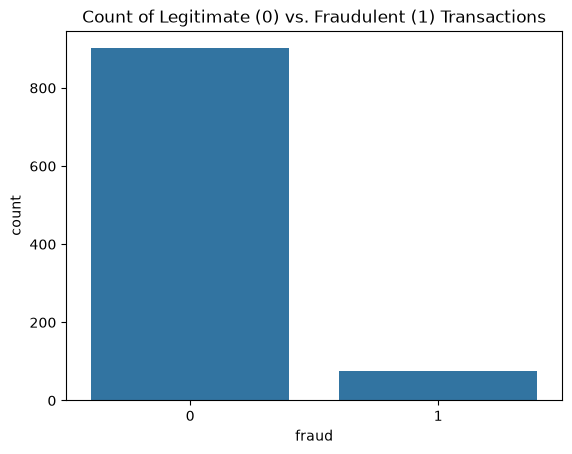

In [8]:
sns.countplot(data=transaction_data, x='fraud')
plt.title('Count of Legitimate (0) vs. Fraudulent (1) Transactions')
plt.show()

**Prompt:** Excellent, now follow the same procedures, but do it for the 'used_pin_number' variable.

**AI:** Claude Sonnet 5.5

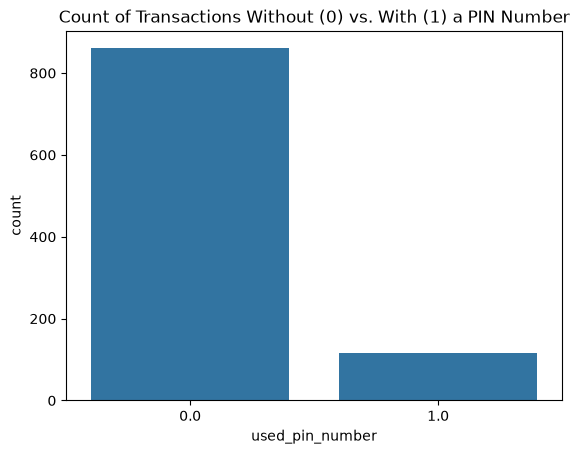

In [9]:
sns.countplot(data=transaction_data, x='used_pin_number')
plt.title('Count of Transactions Without (0) vs. With (1) a PIN Number')
plt.show()

**Prompt:** Do the same thing for the 'repeat_retailer' variable and for the 'online_order' variable.

**AI:** Claude Sonnet 5.5

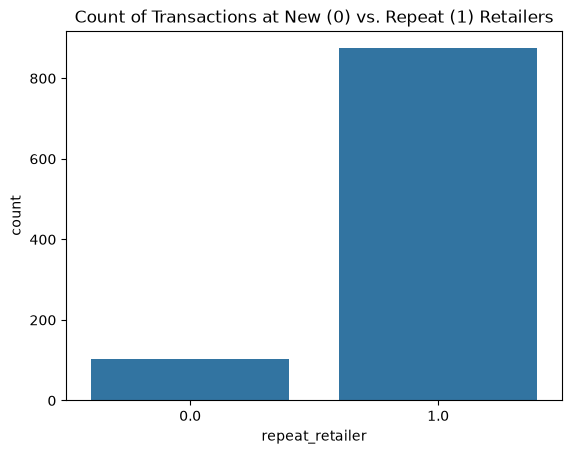

In [10]:
sns.countplot(data=transaction_data, x='repeat_retailer')
plt.title('Count of Transactions at New (0) vs. Repeat (1) Retailers')
plt.show()

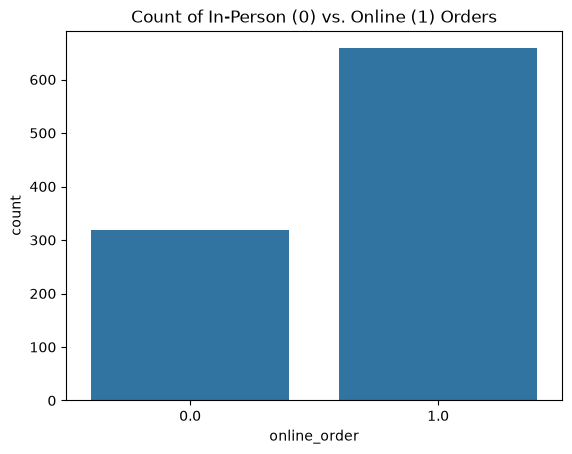

In [11]:
sns.countplot(data=transaction_data, x='online_order')
plt.title('Count of In-Person (0) vs. Online (1) Orders')
plt.show()

**Prompt:** Now, make a histogram of 'ratio_to_median_purchase_price' and set it so there are 30 bins. Make sure to continue adding a title. Once you have completed this, do it for the 'distance_from_home' variable after.

**AI:** Claude Sonnet 5.5

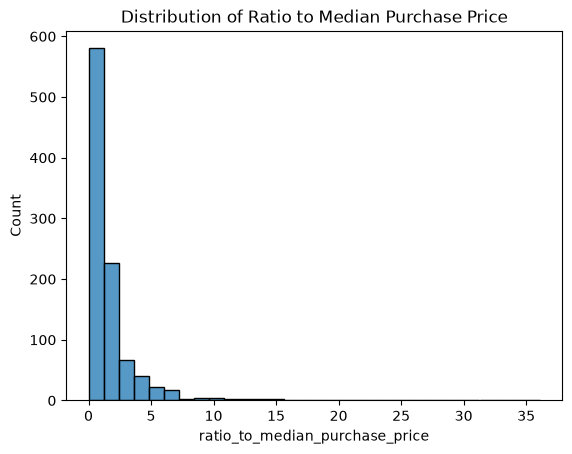

In [12]:
sns.histplot(data=transaction_data, x='ratio_to_median_purchase_price', bins=30)
plt.title('Distribution of Ratio to Median Purchase Price')
plt.show()

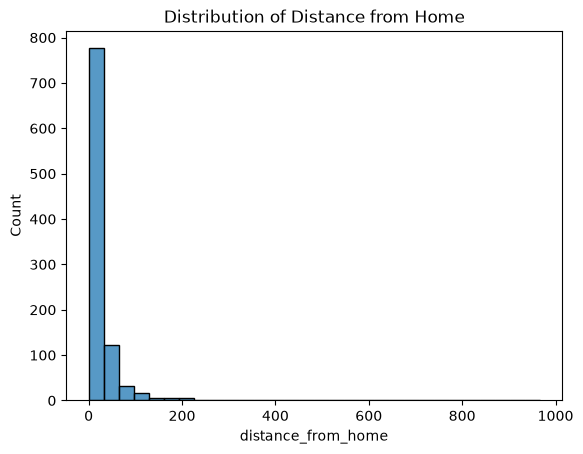

In [13]:
sns.histplot(data=transaction_data, x='distance_from_home', bins=30)
plt.title('Distribution of Distance from Home')
plt.show()

**Prompt:** Perfect, excellent work. Now we are going to get into better visualizations by looking at bivariate visualizations, which is the title of this next section. For the first graph, let's visualize 'used_pin_number'. Let's color the bars green if they are non-fraudulent and red if they are fraudulent. Ensure you add x and y labels and have a title and legend that describes the data. Also add a one-sentence introduction under the section title explaining why we split the variables by fraud.

**AI:** Claude Sonnet 5.5

## Bivariate Visualizations

The plots so far look at one variable at a time. Splitting each variable by fraud status shows how fraudulent and legitimate transactions differ from each other.

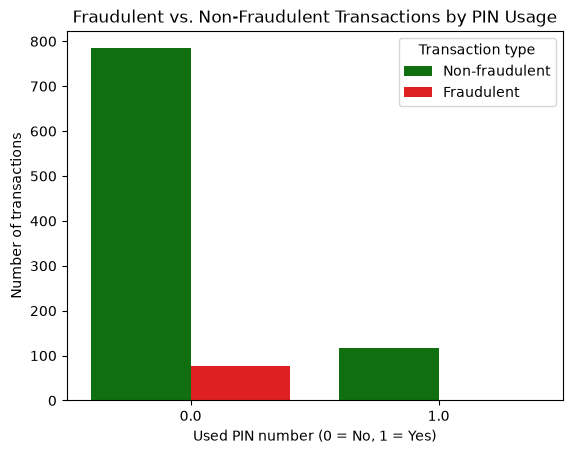

In [14]:
ax = sns.countplot(data=transaction_data, x='used_pin_number', hue='fraud',
                   hue_order=[0, 1], palette={0: 'green', 1: 'red'})
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Non-fraudulent', 'Fraudulent'], title='Transaction type')
plt.title('Fraudulent vs. Non-Fraudulent Transactions by PIN Usage')
plt.xlabel('Used PIN number (0 = No, 1 = Yes)')
plt.ylabel('Number of transactions')
plt.show()

**Prompt:** Now create a percentage bar plot to find the percentage of fraudulent transactions where a pin was used or not. Consider how you might have to group the variables. I'd like you to keep the same colors from the last plot of red for fraudulent and green for non-fraudulent. Continue to use a title, x and y labels, and legend.

**AI:** Claude Sonnet 5.5

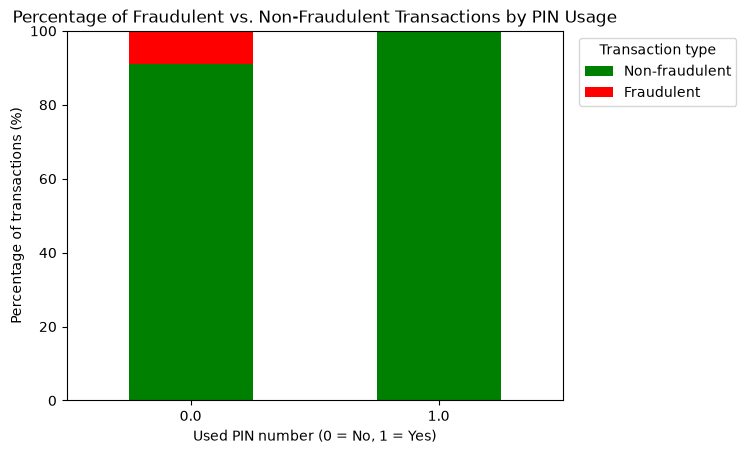

In [15]:
pin_percent = transaction_data.groupby('used_pin_number')['fraud'].value_counts(normalize=True).unstack(fill_value=0) * 100
ax = pin_percent.plot(kind='bar', stacked=True, color=['green', 'red'], rot=0)
ax.legend(['Non-fraudulent', 'Fraudulent'], title='Transaction type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.title('Percentage of Fraudulent vs. Non-Fraudulent Transactions by PIN Usage')
plt.xlabel('Used PIN number (0 = No, 1 = Yes)')
plt.ylabel('Percentage of transactions (%)')
plt.show()

**Prompt:** Well done. Good adaption and everything is looking great so far. The next graph will look at something similar. We are going to look at a count plot to display the number of transactions that were fraud vs non-fraud when there was a chip used or not. After making this plot, visualize the exact same thing, but as a percentage plot. Again, ensure you are using proper titles, labels, and a legend.

**AI:** Claude Sonnet 5.5

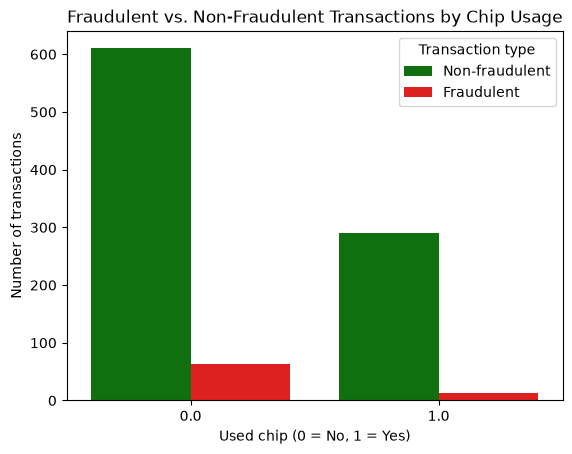

In [16]:
ax = sns.countplot(data=transaction_data, x='used_chip', hue='fraud',
                   hue_order=[0, 1], palette={0: 'green', 1: 'red'})
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Non-fraudulent', 'Fraudulent'], title='Transaction type')
plt.title('Fraudulent vs. Non-Fraudulent Transactions by Chip Usage')
plt.xlabel('Used chip (0 = No, 1 = Yes)')
plt.ylabel('Number of transactions')
plt.show()

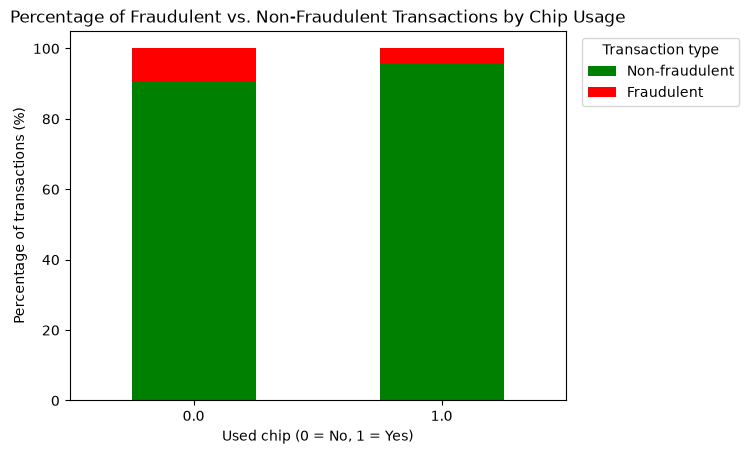

In [17]:
chip_percent = transaction_data.groupby('used_chip')['fraud'].value_counts(normalize=True).unstack(fill_value=0) * 100
ax = chip_percent.plot(kind='bar', stacked=True, color=['green', 'red'], rot=0)
ax.legend(['Non-fraudulent', 'Fraudulent'], title='Transaction type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.title('Percentage of Fraudulent vs. Non-Fraudulent Transactions by Chip Usage')
plt.xlabel('Used chip (0 = No, 1 = Yes)')
plt.ylabel('Percentage of transactions (%)')
plt.show()

**Prompt:** This is great work. Do the same thing with the two graphs (Count plot first and then percentage plot), but do it for whether or not it was an online order.

**AI:** Claude Sonnet 5.5

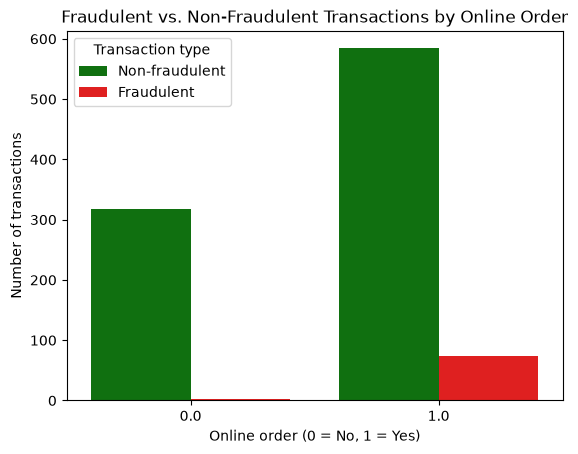

In [18]:
ax = sns.countplot(data=transaction_data, x='online_order', hue='fraud',
                   hue_order=[0, 1], palette={0: 'green', 1: 'red'})
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Non-fraudulent', 'Fraudulent'], title='Transaction type')
plt.title('Fraudulent vs. Non-Fraudulent Transactions by Online Order')
plt.xlabel('Online order (0 = No, 1 = Yes)')
plt.ylabel('Number of transactions')
plt.show()

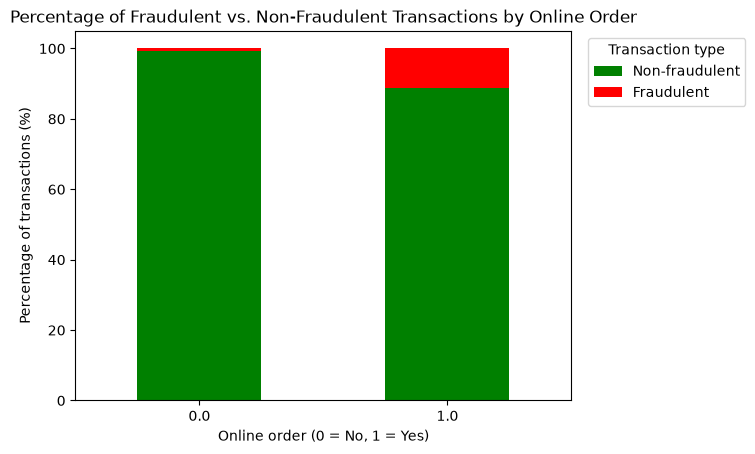

In [19]:

online_percent = transaction_data.groupby('online_order')['fraud'].value_counts(normalize=True).unstack(fill_value=0) * 100
ax = online_percent.plot(kind='bar', stacked=True, color=['green', 'red'], rot=0)
ax.legend(['Non-fraudulent', 'Fraudulent'], title='Transaction type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.title('Percentage of Fraudulent vs. Non-Fraudulent Transactions by Online Order')
plt.xlabel('Online order (0 = No, 1 = Yes)')
plt.ylabel('Percentage of transactions (%)')
plt.show()

**Prompt:** You have continued to do amazing work. Continue it by creating a scatter plot that shows fraud vs non-fraud for the 'distance_from_last_transaction' vs the 'ratio_to_median_purchase_price'.

**AI:** Claude Sonnet 5.5

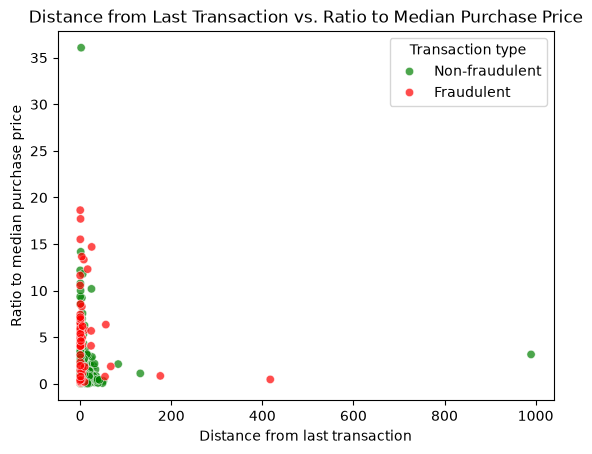

In [20]:
ax = sns.scatterplot(data=transaction_data.sort_values('fraud'),
                     x='distance_from_last_transaction', y='ratio_to_median_purchase_price',
                     hue='fraud', hue_order=[0, 1], palette={0: 'green', 1: 'red'}, alpha=0.7)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Non-fraudulent', 'Fraudulent'], title='Transaction type')
plt.title('Distance from Last Transaction vs. Ratio to Median Purchase Price')
plt.xlabel('Distance from last transaction')
plt.ylabel('Ratio to median purchase price')
plt.show()

**Prompt:** One last request, create a scatterplot similar to the last one you just did that maps 'distance_from_home' and 'ratio_to_median_purchase_price'.

**AI:** Claude Sonnet 5.5

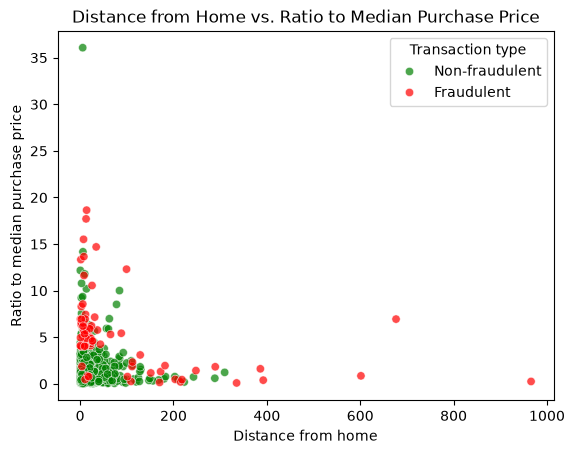

In [21]:
ax = sns.scatterplot(data=transaction_data.sort_values('fraud'),
                     x='distance_from_home', y='ratio_to_median_purchase_price',
                     hue='fraud', hue_order=[0, 1], palette={0: 'green', 1: 'red'}, alpha=0.7)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Non-fraudulent', 'Fraudulent'], title='Transaction type')
plt.title('Distance from Home vs. Ratio to Median Purchase Price')
plt.xlabel('Distance from home')
plt.ylabel('Ratio to median purchase price')
plt.show()